# 02 — Vanda Experiments: Strong and Weak Scaling

This notebook summarizes all Vanda experiments without mixing in local Mac results. Each configuration uses one warm-up followed by five measured runs. Tables and plots report the median, with Q1–Q3 uncertainty bands.

- **Fixed resource decomposition:** 32 CPUs with different MPI rank × OpenMP thread layouts.
- **Strong scaling:** a fixed input graph on 1–128 CPUs.
- **Weak scaling — replica:** BerkStan graph size grows with CPU count.
- **Induced-subgraph scaling:** UK-2002 vertex samples grow with CPU count as a structural comparison.

In [1]:
from pathlib import Path
import os

ROOT = Path.cwd().resolve()
if not (ROOT / 'Makefile').exists():
    ROOT = ROOT.parent
assert (ROOT / 'Makefile').exists(), 'Start Jupyter from the project directory or its notebook subdirectory'
os.chdir(ROOT)
print('Project root located; working directory set successfully.')

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW = ROOT / 'results/vanda/raw'
FIGURES = ROOT / 'results/vanda/figures'
FIGURES.mkdir(parents=True, exist_ok=True)
DATASET_ORDER = ['web-Google', 'web-BerkStan', 'enwiki-2013', 'uk-2002']
FIXED_ORDER = ['1x32', '2x16', '4x8', '8x4', '16x2', '32x1']
CPU_ORDER = [1, 2, 4, 8, 16, 32, 64, 128]
print('Raw Vanda result files:', len(list(RAW.glob('*.csv'))))


Project root located; working directory set successfully.


Raw Vanda result files: 36


## 1. Experimental Design and Resources

| Suite | CPUs | Nodes | Configurations |
|---|---:|---:|---|
| fixed32 | 32 | 1 | 1×32, 2×16, 4×8, 8×4, 16×2, 32×1 |
| comprehensive strong | 1–32 | 1 | every feasible rank×thread factorization |
| comprehensive strong | 64 | 2 | 2×32, 4×16, 8×8, 16×4, 32×2, 64×1 |
| comprehensive strong | 128 | 4 | 4×32, 8×16, 16×8, 32×4, 64×2, 128×1 |

`R×T` denotes MPI ranks × OpenMP threads/rank. Timing uses `solve_seconds` and excludes loading and distribution. The fixed-32 jobs ran only the six 32-CPU layouts on IN-006 and contain no Serial measurement, so this suite is used only for decomposition comparisons. For each graph, the comprehensive 1–32 CPU scope runs Serial and every feasible layout in one PBS job on IN-015. Its speedups therefore use a same-job, same-node Serial denominator; historical Serial records from other job series are not mixed into these ratios.


In [2]:
manifest_path = ROOT / 'results/vanda/submitted_jobs.tsv'
if manifest_path.exists():
    manifest = pd.read_csv(manifest_path, sep='\t')
    display(manifest)
    print(f'Submitted PBS jobs: {len(manifest)}')
else:
    manifest = pd.DataFrame()
    print('Job manifest has not been downloaded yet.')


,job_id,suite,dataset,total_cpus,nodes,memory_per_node
0,1495582.stdct-mgmt-02,fixed32,google,32,1,16gb
1,1495583.stdct-mgmt-02,fixed32,berkstan,32,1,16gb
2,1495584.stdct-mgmt-02,fixed32,enwiki,32,1,32gb
3,1495585.stdct-mgmt-02,fixed32,uk,32,1,48gb
4,1495586.stdct-mgmt-02,strong,google,1,1,4gb
5,1495587.stdct-mgmt-02,strong,google,2,1,8gb
6,1495588.stdct-mgmt-02,strong,google,4,1,8gb
7,1495589.stdct-mgmt-02,strong,google,8,1,8gb
8,1495590.stdct-mgmt-02,strong,google,16,1,8gb
9,1495591.stdct-mgmt-02,strong,google,32,1,16gb


Submitted PBS jobs: 36


## 2. Load, Validate, and Check Completion

In [3]:
files = sorted(RAW.glob('*.csv'))
if not files:
    raise FileNotFoundError('Vanda CSV files are missing; run scripts/vanda/fetch_vanda_results.sh')
runs = pd.concat((pd.read_csv(path).assign(source_file=path.name) for path in files), ignore_index=True)
runs['dataset_name'] = runs['dataset'].map(lambda value: Path(value).stem)
parts = runs['run_id'].str.extract(r'^(fixed32|strong)-(google|berkstan|enwiki|uk)-(\d+x\d+)-rep(\d+)$')
parts.columns = ['suite', 'dataset_key', 'config', 'repetition']
runs = pd.concat([runs, parts], axis=1)
runs['repetition'] = pd.to_numeric(runs['repetition'])
runs['total_cpus'] = runs['mpi_ranks'] * runs['threads_per_rank']
runs['nodes'] = np.where(runs['total_cpus'] <= 32, 1, runs['total_cpus'] // 32)
runs['implementation'] = np.select(
    [runs['mode'].eq('serial'), runs['threads_per_rank'].eq(1)],
    ['serial', 'MPI only'], default='MPI+OpenMP')
runs[['suite', 'dataset_name', 'config', 'implementation', 'repetition',
      'solve_seconds', 'converged']].head()


,suite,dataset_name,config,implementation,repetition,solve_seconds,converged
0,fixed32,web-Google,1x32,MPI+OpenMP,1,0.286444,1
1,fixed32,web-Google,1x32,MPI+OpenMP,2,0.287036,1
2,fixed32,web-Google,1x32,MPI+OpenMP,3,0.286289,1
3,fixed32,web-Google,1x32,MPI+OpenMP,4,0.287792,1
4,fixed32,web-Google,1x32,MPI+OpenMP,5,0.292796,1


In [4]:
strong_configs = ['1x1', '2x1', '1x2', '4x1', '2x2', '8x1', '2x4',
                  '16x1', '4x4', '32x1', '4x8', '64x1', '8x8', '128x1', '16x8']
expected = pd.DataFrame(
    [(suite, dataset, config)
     for dataset in DATASET_ORDER
     for suite, configs in [('fixed32', FIXED_ORDER), ('strong', strong_configs)]
     for config in configs],
    columns=['suite', 'dataset_name', 'config'])
counts = (runs.groupby(['suite', 'dataset_name', 'config'])
          .size().rename('measured_runs').reset_index())
completion = expected.merge(counts, how='left', on=['suite', 'dataset_name', 'config'])
completion['measured_runs'] = completion['measured_runs'].fillna(0).astype(int)
missing = completion[completion['measured_runs'].ne(5)]

checks = pd.Series({
    'result_files_downloaded': len(files),
    'formal_measurements': len(runs),
    'expected_final_measurements': len(expected) * 5,
    'complete_configurations': counts['measured_runs'].eq(5).sum(),
    'expected_configurations': len(expected),
    'all_run_ids_parsed': runs['suite'].notna().all(),
    'all_available_runs_converged': runs['converged'].eq(1).all(),
    'max_residual': runs['residual'].max(),
    'max_rank_sum_error': runs['rank_sum_error'].max(),
})
display(checks.to_frame('value'))
print('Missing or incomplete configurations:')
display(missing)
assert checks['all_run_ids_parsed'] and checks['all_available_runs_converged']
assert counts['measured_runs'].eq(5).all()
assert checks['max_rank_sum_error'] < 1e-9


,value
result_files_downloaded,36
formal_measurements,420
expected_final_measurements,420
complete_configurations,84
expected_configurations,84
all_run_ids_parsed,True
all_available_runs_converged,True
max_residual,0.0
max_rank_sum_error,0.0


Missing or incomplete configurations:


,suite,dataset_name,config,measured_runs


## 3. Median Summary Table

In [5]:
summary = (runs.groupby(['suite', 'dataset_name', 'config', 'implementation',
                         'total_cpus', 'nodes'])
           .agg(runs=('solve_seconds', 'size'),
                median_s=('solve_seconds', 'median'),
                q1_s=('solve_seconds', lambda x: x.quantile(0.25)),
                q3_s=('solve_seconds', lambda x: x.quantile(0.75)),
                min_s=('solve_seconds', 'min'),
                max_s=('solve_seconds', 'max'),
                peak_rss_gib=('peak_rss_bytes', lambda x: x.max() / 1024**3))
           .reset_index())
display(summary.sort_values(['suite', 'dataset_name', 'total_cpus', 'implementation']))


,suite,dataset_name,config,implementation,total_cpus,nodes,runs,median_s,q1_s,q3_s,min_s,max_s,peak_rss_gib
3,fixed32,enwiki-2013,32x1,MPI only,32,1,5,4.159371,4.159272,4.160371,4.158082,4.167599,0.546474
0,fixed32,enwiki-2013,16x2,MPI+OpenMP,32,1,5,3.849540,3.848477,3.849619,3.837033,3.854789,0.571556
1,fixed32,enwiki-2013,1x32,MPI+OpenMP,32,1,5,2.000160,1.994431,2.000669,1.994006,2.005228,0.952824
2,fixed32,enwiki-2013,2x16,MPI+OpenMP,32,1,5,2.402042,2.394582,2.411806,2.392629,2.414131,0.762020
4,fixed32,enwiki-2013,4x8,MPI+OpenMP,32,1,5,3.205981,3.201378,3.206080,3.195660,3.220157,0.656746
...,...,...,...,...,...,...,...,...,...,...,...,...,...
80,strong,web-Google,4x8,MPI+OpenMP,32,1,5,0.471945,0.470741,0.473902,0.467127,0.474790,0.067032
81,strong,web-Google,64x1,MPI only,64,2,5,1.598931,1.539596,1.609833,1.490973,1.639116,0.061943
83,strong,web-Google,8x8,MPI+OpenMP,64,2,5,0.599478,0.595223,0.607636,0.590796,0.607960,0.063477
69,strong,web-Google,128x1,MPI only,128,4,5,2.058675,1.770705,2.140403,1.763700,2.301716,0.061890


## 4. Experiment 1: MPI/OpenMP Decomposition with 32 CPUs

Saved: results/vanda/figures/vanda_fixed32_decomposition.png


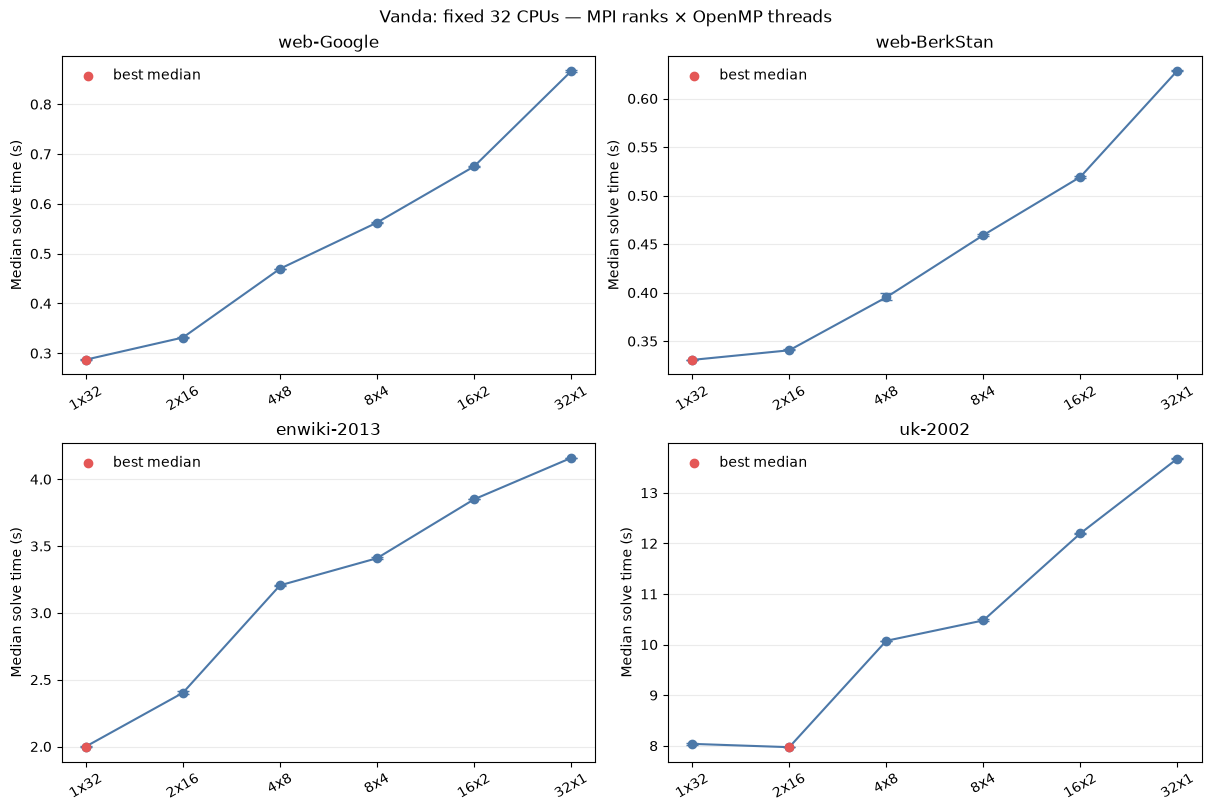

In [6]:
fixed = summary[summary['suite'].eq('fixed32')].copy()
fixed['config'] = pd.Categorical(fixed['config'], FIXED_ORDER, ordered=True)
fixed = fixed.sort_values(['dataset_name', 'config'])
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for ax, dataset in zip(axes.flat, DATASET_ORDER):
    part = fixed[fixed['dataset_name'].eq(dataset)].set_index('config').reindex(FIXED_ORDER)
    y = part['median_s'].to_numpy()
    ax.errorbar(FIXED_ORDER, y, yerr=[y - part['q1_s'].to_numpy(),
                                      part['q3_s'].to_numpy() - y],
                marker='o', capsize=4, color='#4C78A8')
    best = int(np.nanargmin(y))
    ax.scatter(FIXED_ORDER[best], y[best], color='#E45756', zorder=3, label='best median')
    ax.set_title(dataset)
    ax.set_ylabel('Median solve time (s)')
    ax.tick_params(axis='x', rotation=30)
    ax.grid(axis='y', alpha=0.25)
    ax.legend(frameon=False)
fig.suptitle('Vanda: fixed 32 CPUs — MPI ranks × OpenMP threads')
fixed_path = FIGURES / 'vanda_fixed32_decomposition.png'
fig.savefig(fixed_path, dpi=180, bbox_inches='tight')
print('Saved:', fixed_path.relative_to(ROOT))
plt.show()


## 5. Experiment 2: Comprehensive Strong Scaling on 1–128 CPUs

The supplementary sweep tests every feasible factorization of total CPUs into MPI ranks and OpenMP threads, with at most 32 threads per rank. For 1–32 CPUs, all layouts run in one single-node job per graph on IN-015, including Serial, 1×32 Hybrid, and 32×1 MPI-only. At 64 and 128 CPUs, all six feasible layouts run in one two-node or four-node job per graph. Each configuration uses one warm-up and five measured repetitions. This gives 33 configurations and 165 measured runs per graph, or 660 measurements overall. Reported speedups use only the Serial median from the same comprehensive per-graph job.


In [7]:
STRONG_FULL_RAW = ROOT / 'results/vanda/strong_full/raw'
strong_files = sorted(STRONG_FULL_RAW.glob('*.csv'))
if not strong_files:
    raise FileNotFoundError(f'No supplementary strong-scaling CSVs found in {STRONG_FULL_RAW}')

strong_runs = pd.concat((pd.read_csv(path).assign(source_file=path.name)
                         for path in strong_files), ignore_index=True)
parts = strong_runs['run_id'].str.extract(
    r'^strongfull-(google|berkstan|enwiki|uk)-(\d+)-(\d+)x(\d+)-rep(\d+)$')
parts.columns = ['dataset_key', 'cpus_from_id', 'ranks_from_id', 'threads_from_id', 'repetition']
for column in ['cpus_from_id', 'ranks_from_id', 'threads_from_id', 'repetition']:
    parts[column] = pd.to_numeric(parts[column])
strong_runs = pd.concat([strong_runs, parts], axis=1)
labels = {'google': 'web-Google', 'berkstan': 'web-BerkStan',
          'enwiki': 'enwiki-2013', 'uk': 'uk-2002'}
strong_runs['dataset_name'] = strong_runs['dataset_key'].map(labels)
strong_runs['total_cpus'] = strong_runs['mpi_ranks'] * strong_runs['threads_per_rank']
strong_runs['config'] = (strong_runs['mpi_ranks'].astype(str) + 'x' +
                         strong_runs['threads_per_rank'].astype(str))
strong_runs['implementation'] = np.select(
    [strong_runs['mode'].eq('serial'), strong_runs['threads_per_rank'].eq(1)],
    ['serial', 'MPI only'], default='MPI+OpenMP')
strong_runs['nodes'] = np.where(strong_runs['total_cpus'] <= 32, 1,
                                strong_runs['total_cpus'] // 32)

expected_layouts = {
    cpus: [f'{cpus // threads}x{threads}' for threads in [32, 16, 8, 4, 2, 1]
           if cpus % threads == 0]
    for cpus in CPU_ORDER
}
expected_layouts[1] = ['1x1']
expected = pd.DataFrame(
    [(dataset, cpus, config) for dataset in DATASET_ORDER
     for cpus in CPU_ORDER for config in expected_layouts[cpus]],
    columns=['dataset_name', 'total_cpus', 'config'])
counts = (strong_runs.groupby(['dataset_name', 'total_cpus', 'config'])
          .size().rename('measured_runs').reset_index())
completion = expected.merge(counts, how='left', on=['dataset_name', 'total_cpus', 'config'])
completion['measured_runs'] = completion['measured_runs'].fillna(0).astype(int)

single_scope = strong_runs[strong_runs['total_cpus'].le(32)]
single_scope_files = single_scope.groupby('dataset_name')['source_file'].nunique()
single_scope_hosts = single_scope.groupby('dataset_name')['hostname'].agg(lambda x: sorted(set(x)))

checks = pd.Series({
    'result_files': len(strong_files),
    'formal_measurements': len(strong_runs),
    'expected_measurements': 660,
    'configurations': len(counts),
    'expected_configurations': 132,
    'all_run_ids_parsed': strong_runs['dataset_key'].notna().all(),
    'five_runs_per_configuration': completion['measured_runs'].eq(5).all(),
    'all_runs_converged': strong_runs['converged'].eq(1).all(),
    'single_scope_one_file_per_graph': single_scope_files.eq(1).all(),
    'single_scope_host_is_IN-015': single_scope_hosts.map(lambda x: x == ['IN-015']).all(),
    'fixed32_has_no_serial_rows': not ((runs['suite'].eq('fixed32')) & (runs['mode'].eq('serial'))).any(),
    'max_residual': strong_runs['residual'].max(),
    'max_rank_sum_error': strong_runs['rank_sum_error'].abs().max(),
})
display(checks.to_frame('value'))
assert len(strong_runs) == 660 and len(counts) == 132
assert checks['all_run_ids_parsed'] and checks['five_runs_per_configuration']
assert checks['all_runs_converged'] and checks['max_rank_sum_error'] < 1e-9
assert checks['single_scope_one_file_per_graph'] and checks['single_scope_host_is_IN-015']
assert checks['fixed32_has_no_serial_rows']

strong = (strong_runs.groupby(['dataset_name', 'config', 'implementation',
                                'total_cpus', 'nodes', 'mpi_ranks', 'threads_per_rank'])
          .agg(runs=('solve_seconds', 'size'),
               median_s=('solve_seconds', 'median'),
               q1_s=('solve_seconds', lambda x: x.quantile(0.25)),
               q3_s=('solve_seconds', lambda x: x.quantile(0.75)),
               min_s=('solve_seconds', 'min'),
               max_s=('solve_seconds', 'max'),
               hostname=('hostname', lambda x: ','.join(sorted(set(x)))))
          .reset_index())
serial_baseline = (strong[strong['implementation'].eq('serial')]
                   .set_index('dataset_name')['median_s'])
strong['serial_median_s'] = strong['dataset_name'].map(serial_baseline)
strong['speedup'] = strong['serial_median_s'] / strong['median_s']
strong['efficiency'] = strong['speedup'] / strong['total_cpus']
strong_impl_best = strong.loc[
    strong.groupby(['dataset_name', 'total_cpus', 'implementation'])['median_s'].idxmin()
].copy()
strong_best = strong.loc[
    strong.groupby(['dataset_name', 'total_cpus'])['median_s'].idxmin()
].copy()
display(strong.sort_values(['dataset_name', 'total_cpus', 'threads_per_rank']))

,value
result_files,12
formal_measurements,660
expected_measurements,660
configurations,132
expected_configurations,132
all_run_ids_parsed,True
five_runs_per_configuration,True
all_runs_converged,True
single_scope_one_file_per_graph,True
single_scope_host_is_IN-015,True


,dataset_name,config,implementation,total_cpus,nodes,mpi_ranks,threads_per_rank,runs,median_s,q1_s,q3_s,min_s,max_s,hostname,serial_median_s,speedup,efficiency
5,enwiki-2013,1x1,serial,1,1,1,1,5,20.640911,20.568733,20.931725,20.389152,23.238753,IN-015,20.640911,1.000000,1.000000
11,enwiki-2013,2x1,MPI only,2,1,2,1,5,15.146889,15.140653,15.176762,15.101049,15.181325,IN-015,20.640911,1.362716,0.681358
7,enwiki-2013,1x2,MPI+OpenMP,2,1,1,2,5,13.661184,13.623816,13.713708,13.463976,13.865822,IN-015,20.640911,1.510917,0.755458
20,enwiki-2013,4x1,MPI only,4,1,4,1,5,9.481175,9.480508,9.486508,9.452153,9.487994,IN-015,20.640911,2.177041,0.544260
13,enwiki-2013,2x2,MPI+OpenMP,4,1,2,2,5,8.690807,8.675027,8.722148,8.669110,8.741836,IN-015,20.640911,2.375028,0.593757
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
126,web-Google,64x2,MPI+OpenMP,128,4,64,2,5,1.550115,1.542707,1.616925,1.540383,1.764306,IN-002,3.378885,2.179764,0.017029
118,web-Google,32x4,MPI+OpenMP,128,4,32,4,5,1.084800,1.015412,1.136509,1.011193,1.150744,IN-002,3.378885,3.114754,0.024334
103,web-Google,16x8,MPI+OpenMP,128,4,16,8,5,0.680821,0.675434,0.689954,0.640341,0.700834,IN-002,3.378885,4.962954,0.038773
128,web-Google,8x16,MPI+OpenMP,128,4,8,16,5,0.594586,0.585976,0.600312,0.563019,0.603653,IN-002,3.378885,5.682754,0.044397


Saved: results/vanda/figures/vanda_strong_runtime.png


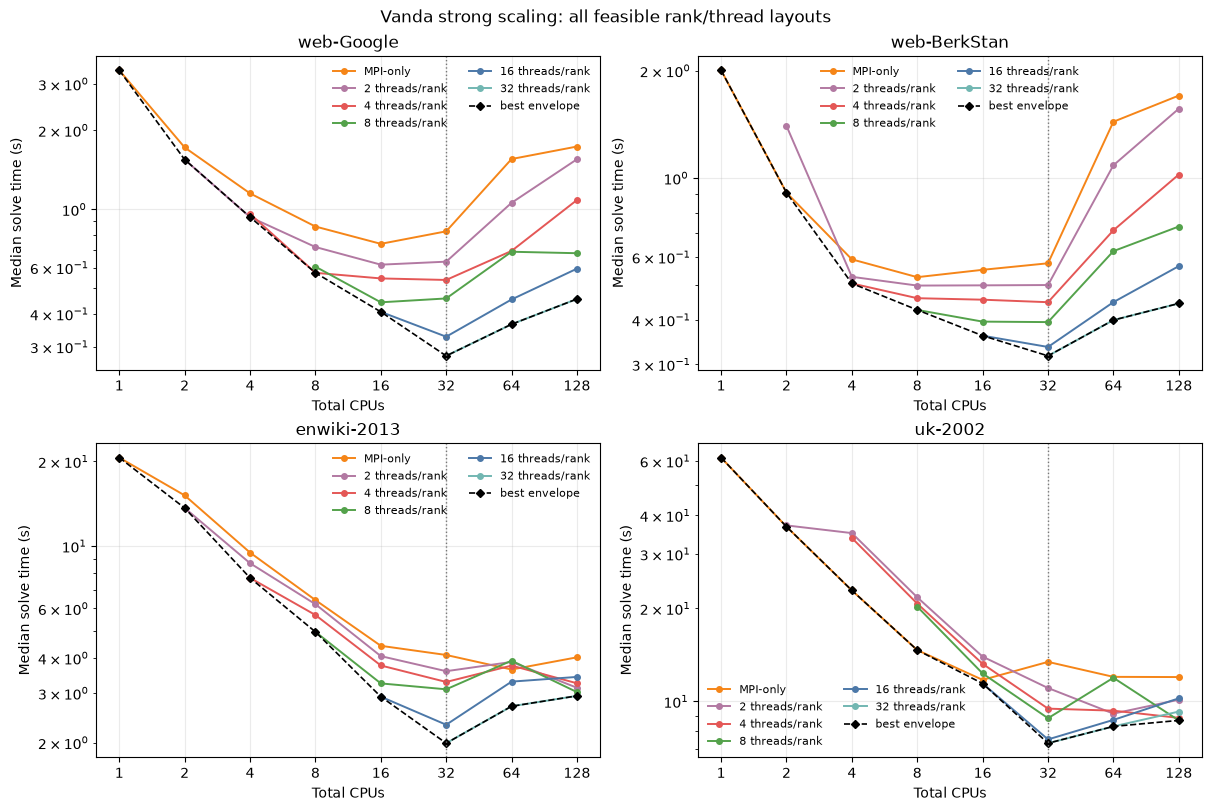

In [8]:
thread_colors = {1: '#F58518', 2: '#B279A2', 4: '#E45756',
                 8: '#54A24B', 16: '#4C78A8', 32: '#72B7B2'}
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for ax, dataset in zip(axes.flat, DATASET_ORDER):
    part_all = strong[strong['dataset_name'].eq(dataset)]
    for threads in [1, 2, 4, 8, 16, 32]:
        part = part_all[part_all['threads_per_rank'].eq(threads)].sort_values('total_cpus')
        if part.empty:
            continue
        label = 'MPI-only' if threads == 1 else f'{threads} threads/rank'
        ax.plot(part['total_cpus'], part['median_s'], marker='o', markersize=4,
                label=label, color=thread_colors[threads], linewidth=1.4)
    envelope = strong_best[strong_best['dataset_name'].eq(dataset)].sort_values('total_cpus')
    ax.plot(envelope['total_cpus'], envelope['median_s'], color='black', marker='D',
            markersize=4, linestyle='--', linewidth=1.2, label='best envelope')
    ax.set_xscale('log', base=2); ax.set_yscale('log')
    ax.set_xticks(CPU_ORDER, CPU_ORDER)
    ax.axvline(32, color='#777777', linestyle=':', linewidth=1)
    ax.set_title(dataset); ax.set_xlabel('Total CPUs'); ax.set_ylabel('Median solve time (s)')
    ax.grid(alpha=0.25); ax.legend(frameon=False, fontsize=8, ncol=2)
fig.suptitle('Vanda strong scaling: all feasible rank/thread layouts')
runtime_path = FIGURES / 'vanda_strong_runtime.png'
fig.savefig(runtime_path, dpi=180, bbox_inches='tight')
print('Saved:', runtime_path.relative_to(ROOT))
plt.show()

Saved: results/vanda/figures/vanda_strong_speedup.png


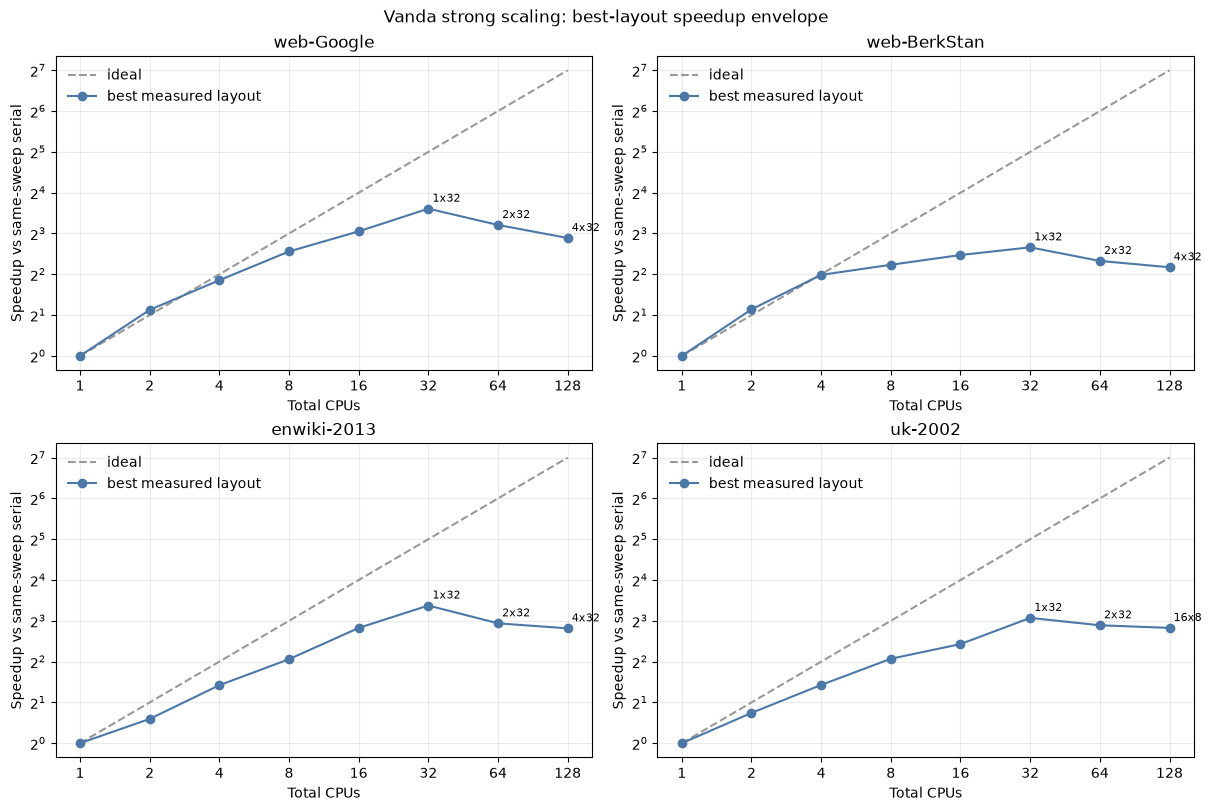

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for ax, dataset in zip(axes.flat, DATASET_ORDER):
    part = strong_best[strong_best['dataset_name'].eq(dataset)].sort_values('total_cpus')
    ax.plot(CPU_ORDER, CPU_ORDER, '--', color='#999999', label='ideal')
    ax.plot(part['total_cpus'], part['speedup'], marker='o', color='#4C78A8',
            label='best measured layout')
    for row in part[part['total_cpus'].isin([32, 64, 128])].itertuples():
        ax.annotate(row.config, (row.total_cpus, row.speedup), xytext=(3, 5),
                    textcoords='offset points', fontsize=8)
    ax.set_xscale('log', base=2); ax.set_yscale('log', base=2)
    ax.set_xticks(CPU_ORDER, CPU_ORDER); ax.set_title(dataset)
    ax.set_xlabel('Total CPUs'); ax.set_ylabel('Speedup vs same-sweep serial')
    ax.grid(alpha=0.25); ax.legend(frameon=False)
fig.suptitle('Vanda strong scaling: best-layout speedup envelope')
speedup_path = FIGURES / 'vanda_strong_speedup.png'
fig.savefig(speedup_path, dpi=180, bbox_inches='tight')
print('Saved:', speedup_path.relative_to(ROOT))
plt.show()

Saved: results/vanda/figures/vanda_strong_efficiency.png


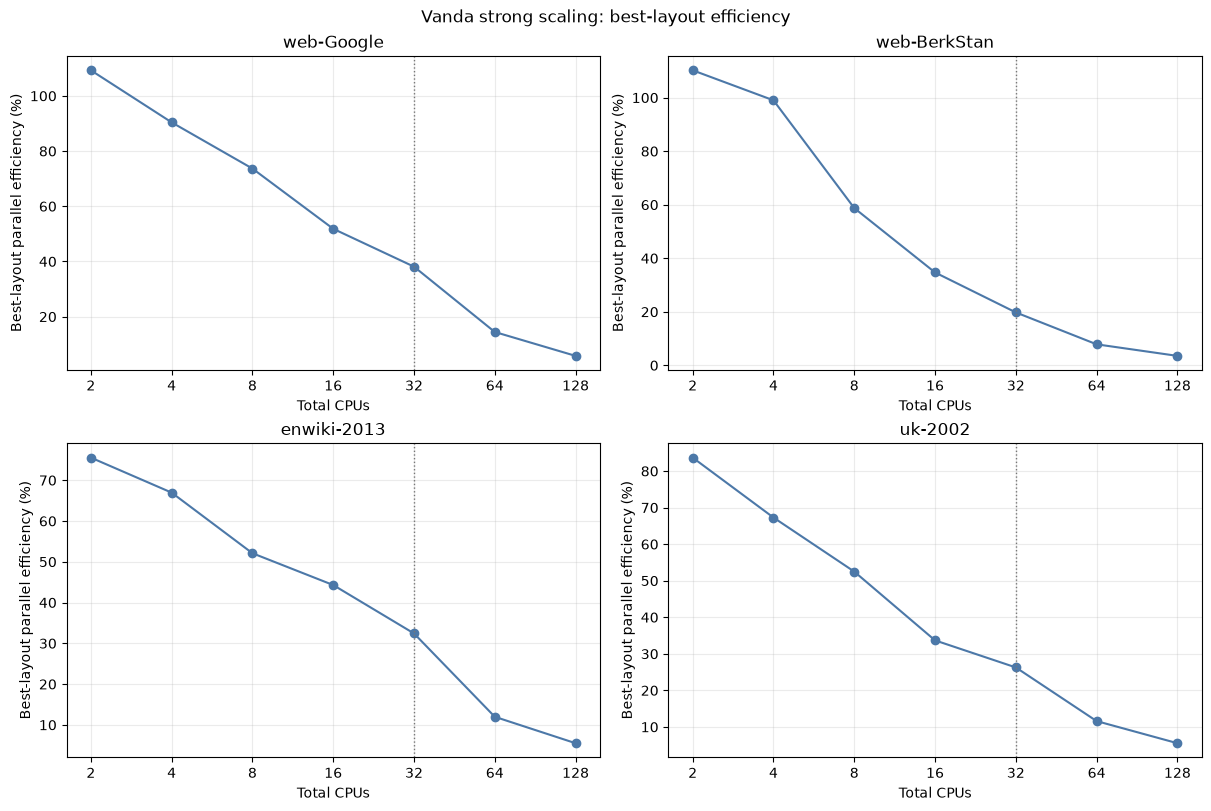

In [10]:
parallel_best = strong_best[strong_best['total_cpus'].gt(1)].copy()
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for ax, dataset in zip(axes.flat, DATASET_ORDER):
    part = parallel_best[parallel_best['dataset_name'].eq(dataset)].sort_values('total_cpus')
    ax.plot(part['total_cpus'], 100 * part['efficiency'], marker='o', color='#4C78A8')
    ax.set_xscale('log', base=2); ax.set_xticks(CPU_ORDER[1:], CPU_ORDER[1:])
    ax.axvline(32, color='#777777', linestyle=':', linewidth=1)
    ax.set_title(dataset); ax.set_xlabel('Total CPUs')
    ax.set_ylabel('Best-layout parallel efficiency (%)'); ax.grid(alpha=0.25)
fig.suptitle('Vanda strong scaling: best-layout efficiency')
efficiency_path = FIGURES / 'vanda_strong_efficiency.png'
fig.savefig(efficiency_path, dpi=180, bbox_inches='tight')
print('Saved:', efficiency_path.relative_to(ROOT))
plt.show()

## 6. Layout Coverage and Best Observed Configurations

The first table gives the selected layout and median time at every CPU count. The second table gives the global minimum for each graph. Selection occurs only after all feasible layouts at that CPU count have been measured.

In [11]:
best_display = strong_best.copy()
best_display['entry'] = best_display.apply(
    lambda row: f"{row['config']} / {row['median_s']:.3f} s", axis=1)
coverage_table = (best_display.pivot(index='total_cpus', columns='dataset_name', values='entry')
                  .reindex(index=CPU_ORDER, columns=DATASET_ORDER))
coverage_table.index.name = 'Total CPUs'
display(coverage_table)

global_best = strong.loc[strong.groupby('dataset_name')['median_s'].idxmin()].copy()
global_best = global_best[['dataset_name', 'config', 'total_cpus', 'median_s',
                           'speedup', 'efficiency', 'hostname']]
global_best['efficiency_percent'] = 100 * global_best['efficiency']
display(global_best.sort_values('dataset_name'))

dataset_name,web-Google,web-BerkStan,enwiki-2013,uk-2002
Total CPUs,,,,
1,1x1 / 3.379 s,1x1 / 2.005 s,1x1 / 20.641 s,1x1 / 61.542 s
2,1x2 / 1.546 s,2x1 / 0.909 s,1x2 / 13.661 s,2x1 / 36.774 s
4,2x2 / 0.934 s,1x4 / 0.506 s,1x4 / 7.707 s,4x1 / 22.868 s
8,2x4 / 0.573 s,1x8 / 0.427 s,1x8 / 4.953 s,8x1 / 14.656 s
16,1x16 / 0.407 s,1x16 / 0.361 s,1x16 / 2.913 s,1x16 / 11.422 s
32,1x32 / 0.277 s,1x32 / 0.317 s,1x32 / 1.989 s,1x32 / 7.320 s
64,2x32 / 0.365 s,2x32 / 0.399 s,2x32 / 2.693 s,2x32 / 8.296 s
128,4x32 / 0.456 s,4x32 / 0.445 s,4x32 / 2.932 s,16x8 / 8.677 s


,dataset_name,config,total_cpus,median_s,speedup,efficiency,hostname,efficiency_percent
8,enwiki-2013,1x32,32,1.989472,10.375072,0.324221,IN-015,32.422100
41,uk-2002,1x32,32,7.320134,8.407217,0.262726,IN-015,26.272553
74,web-BerkStan,1x32,32,0.317001,6.323444,0.197608,IN-015,19.760761
107,web-Google,1x32,32,0.277025,12.197033,0.381157,IN-015,38.115729


## 7. Update and Reproduce

On Vanda, enter the extracted project root (the directory containing `Makefile`) and submit the comprehensive strong-scaling and weak/structural-scaling suites:

```bash
test -f Makefile && test -d scripts/vanda
bash scripts/vanda/submit_vanda_strong_full.sh "$PWD"
bash scripts/vanda/submit_vanda_weak.sh "$PWD" "/scratch/$USER/DSA5208_Project3/data/weak"
```

The strong-scaling submitter creates four single-node jobs and eight multi-node jobs. Each strong-scaling job keeps all layouts for its graph/resource scope together. The weak-scaling submitter creates one preparation job followed by twelve dependent measurement jobs. From a local copy of the project, fetch the completed result directories and run all cells again. The saved CSVs included with the project allow notebook reproduction without Vanda access.

Each CSV row is one measured run. Warm-ups appear only in PBS logs.

## 8. Weak-Scaling Design

Both suites use 4, 8, 16, 32, 64, and 128 CPUs on 1, 1, 1, 1, 2, and 4 nodes. MPI-only uses `P×1`; hybrid uses four threads per rank (`P/4×4`). Each configuration has one warm-up and five measured runs.

| CPUs | Nodes | BerkStan replicas | UK vertex fraction | MPI only | MPI+OpenMP |
|---:|---:|---:|---:|---:|---:|
| 4 | 1 | 1 | 1/32 | 4×1 | 1×4 |
| 8 | 1 | 2 | 1/16 | 8×1 | 2×4 |
| 16 | 1 | 4 | 1/8 | 16×1 | 4×4 |
| 32 | 1 | 8 | 1/4 | 32×1 | 8×4 |
| 64 | 2 | 16 | 1/2 | 64×1 | 16×4 |
| 128 | 4 | 32 | 1 | 128×1 | 32×4 |

BerkStan replicas keep N/P, M/P, mean degree, and iteration count constant, giving strict weak scaling. UK uses nested uniform vertex-induced samples with seed 5208; N/P is nearly constant, but the induced edge count is not linear, so this is a structural comparison.

## 9. Load and Validate Weak-Scaling Results

In [12]:
WEAK_RAW = ROOT / 'results/vanda/weak/raw'
weak_files = sorted(WEAK_RAW.glob('*.csv'))
if not weak_files:
    raise FileNotFoundError('Weak-scaling CSV files are missing')
weak_runs = pd.concat((pd.read_csv(path).assign(source_file=path.name)
                       for path in weak_files), ignore_index=True)
weak_parts = weak_runs['run_id'].str.extract(
    r'^weak-(berkstan|uk)-([^-]+)-(\d+)x(\d+)-rep(\d+)$')
weak_parts.columns = ['family', 'scale', 'ranks_from_id', 'threads_from_id', 'repetition']
weak_runs = pd.concat([weak_runs, weak_parts], axis=1)
for column in ['ranks_from_id', 'threads_from_id', 'repetition']:
    weak_runs[column] = pd.to_numeric(weak_runs[column])
weak_runs['total_cpus'] = weak_runs['mpi_ranks'] * weak_runs['threads_per_rank']
weak_runs['nodes'] = np.where(weak_runs['total_cpus'] <= 32, 1, weak_runs['total_cpus'] // 32)
weak_runs['implementation'] = np.where(weak_runs['mode'].eq('mpi'), 'MPI only', 'MPI+OpenMP')
weak_counts = (weak_runs.groupby(['family','scale','total_cpus','implementation'])
               .size().rename('measured_runs').reset_index())
weak_checks = pd.Series({
    'result_files': len(weak_files),
    'formal_measurements': len(weak_runs),
    'configurations': len(weak_counts),
    'all_run_ids_parsed': weak_runs['family'].notna().all(),
    'five_runs_per_configuration': weak_counts['measured_runs'].eq(5).all(),
    'all_converged': weak_runs['converged'].eq(1).all(),
    'max_residual': weak_runs['residual'].max(),
    'max_rank_sum_error': weak_runs['rank_sum_error'].max(),
})
display(weak_checks.to_frame('value'))
assert len(weak_files) == 12 and len(weak_runs) == 120 and len(weak_counts) == 24
assert weak_checks['all_run_ids_parsed'] and weak_checks['five_runs_per_configuration']
assert weak_checks['all_converged'] and weak_checks['max_rank_sum_error'] < 1e-9

,value
result_files,12
formal_measurements,120
configurations,24
all_run_ids_parsed,True
five_runs_per_configuration,True
all_converged,True
max_residual,0.0
max_rank_sum_error,0.0


## 10. Actual Workload and Median Summary

In [13]:
weak_summary = (weak_runs.groupby(['family','scale','total_cpus','nodes','implementation'])
                .agg(runs=('solve_seconds','size'),
                     median_s=('solve_seconds','median'),
                     q1_s=('solve_seconds',lambda x:x.quantile(0.25)),
                     q3_s=('solve_seconds',lambda x:x.quantile(0.75)),
                     vertices=('vertices','first'),
                     edges=('edges','first'),
                     iterations=('iterations','median'),
                     peak_rss_gib=('peak_rss_bytes',lambda x:x.max()/1024**3))
                .reset_index())
weak_summary['vertices_per_cpu'] = weak_summary['vertices'] / weak_summary['total_cpus']
weak_summary['edges_per_cpu'] = weak_summary['edges'] / weak_summary['total_cpus']
weak_summary['time_per_iteration_ms'] = 1000 * weak_summary['median_s'] / weak_summary['iterations']
weak_base = (weak_summary[weak_summary['total_cpus'].eq(4)]
             .set_index(['family','implementation'])['median_s'])
weak_summary['weak_efficiency'] = weak_summary.apply(
    lambda row: weak_base[row['family'],row['implementation']] / row['median_s'], axis=1)

weak_workloads = (weak_summary.drop_duplicates(['family','scale','total_cpus'])
                  [['family','scale','total_cpus','nodes','vertices','edges',
                    'vertices_per_cpu','edges_per_cpu','iterations']]
                  .sort_values(['family','total_cpus']))
display(weak_workloads)
display(weak_summary.sort_values(['family','total_cpus','implementation']))

,family,scale,total_cpus,nodes,vertices,edges,vertices_per_cpu,edges_per_cpu,iterations
0,berkstan,1,4,1,685230,7600595,171307.500000,1.900149e+06,148.0
4,berkstan,2,8,1,1370460,15201190,171307.500000,1.900149e+06,148.0
8,berkstan,4,16,1,2740920,30402380,171307.500000,1.900149e+06,148.0
10,berkstan,8,32,1,5481840,60804760,171307.500000,1.900149e+06,148.0
2,berkstan,16,64,2,10963680,121609520,171307.500000,1.900149e+06,148.0
6,berkstan,32,128,4,21927360,243219040,171307.500000,1.900149e+06,148.0
18,uk,1of32,4,1,577948,472690,144487.000000,1.181725e+05,134.0
14,uk,1of16,8,1,1156918,1515707,144614.750000,1.894634e+05,138.0
22,uk,1of8,16,1,2314931,5269826,144683.187500,3.293641e+05,141.0
20,uk,1of4,32,1,4628783,19701356,144649.468750,6.156674e+05,142.0


,family,scale,total_cpus,nodes,implementation,runs,median_s,q1_s,q3_s,vertices,edges,iterations,peak_rss_gib,vertices_per_cpu,edges_per_cpu,time_per_iteration_ms,weak_efficiency
0,berkstan,1,4,1,MPI only,5,1.021259,1.020814,1.022531,685230,7600595,148.0,0.072239,171307.500000,1.900149e+06,6.900402,1.000000
1,berkstan,1,4,1,MPI+OpenMP,5,0.896624,0.896027,0.896775,685230,7600595,148.0,0.098614,171307.500000,1.900149e+06,6.058267,1.000000
4,berkstan,2,8,1,MPI only,5,1.305158,1.300052,1.433467,1370460,15201190,148.0,0.123428,171307.500000,1.900149e+06,8.818635,0.782480
5,berkstan,2,8,1,MPI+OpenMP,5,0.950495,0.941387,0.961849,1370460,15201190,148.0,0.152363,171307.500000,1.900149e+06,6.422262,0.943323
8,berkstan,4,16,1,MPI only,5,1.871704,1.810520,1.903953,2740920,30402380,148.0,0.225800,171307.500000,1.900149e+06,12.646649,0.545631
9,berkstan,4,16,1,MPI+OpenMP,5,1.208436,1.205985,1.219790,2740920,30402380,148.0,0.253048,171307.500000,1.900149e+06,8.165105,0.741971
10,berkstan,8,32,1,MPI only,5,3.854927,3.852705,3.858320,5481840,60804760,148.0,0.433704,171307.500000,1.900149e+06,26.046805,0.264923
11,berkstan,8,32,1,MPI+OpenMP,5,3.000690,2.929940,3.028931,5481840,60804760,148.0,0.458145,171307.500000,1.900149e+06,20.274931,0.298806
2,berkstan,16,64,2,MPI only,5,6.893207,6.883550,6.893797,10963680,121609520,148.0,0.842697,171307.500000,1.900149e+06,46.575722,0.148154
3,berkstan,16,64,2,MPI+OpenMP,5,5.716191,5.701070,5.741856,10963680,121609520,148.0,0.868092,171307.500000,1.900149e+06,38.622914,0.156857


### Workload Check

BerkStan replica keeps vertices/CPU, edges/CPU, and 148 iterations constant, satisfying strict weak scaling. UK induced keeps vertices/CPU nearly constant, but edges/CPU rises substantially; its iteration count also changes from 134 to about 141–143. The UK curve therefore includes changes in graph structure and computational density.

Saved: results/vanda/figures/vanda_weak_workload_per_cpu.png


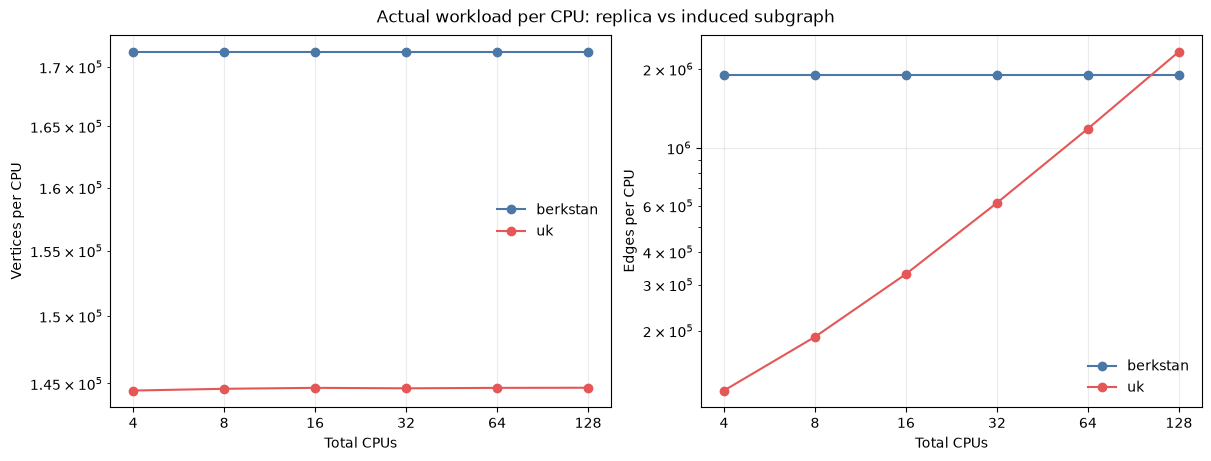

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
family_colors = {'berkstan':'#4C78A8','uk':'#E45756'}
for family in ['berkstan','uk']:
    part = weak_workloads[weak_workloads['family'].eq(family)]
    axes[0].plot(part['total_cpus'], part['vertices_per_cpu'], marker='o',
                 label=family, color=family_colors[family])
    axes[1].plot(part['total_cpus'], part['edges_per_cpu'], marker='o',
                 label=family, color=family_colors[family])
for ax, ylabel in zip(axes, ['Vertices per CPU','Edges per CPU']):
    ax.set_xscale('log',base=2)
    ax.set_yscale('log')
    ax.set_xticks([4,8,16,32,64,128],[4,8,16,32,64,128])
    ax.set_xlabel('Total CPUs')
    ax.set_ylabel(ylabel)
    ax.grid(alpha=.25)
    ax.legend(frameon=False)
fig.suptitle('Actual workload per CPU: replica vs induced subgraph')
workload_path = FIGURES / 'vanda_weak_workload_per_cpu.png'
fig.savefig(workload_path,dpi=180,bbox_inches='tight')
print('Saved:', workload_path.relative_to(ROOT))
plt.show()

## 11. Weak-Scaling Runtime and Efficiency

For each graph family and implementation, the 4-CPU median is the baseline: `weak efficiency = T₄ / Tₚ`. Ideal weak scaling keeps runtime flat and efficiency at 100%.

Saved: results/vanda/figures/vanda_weak_runtime_efficiency.png


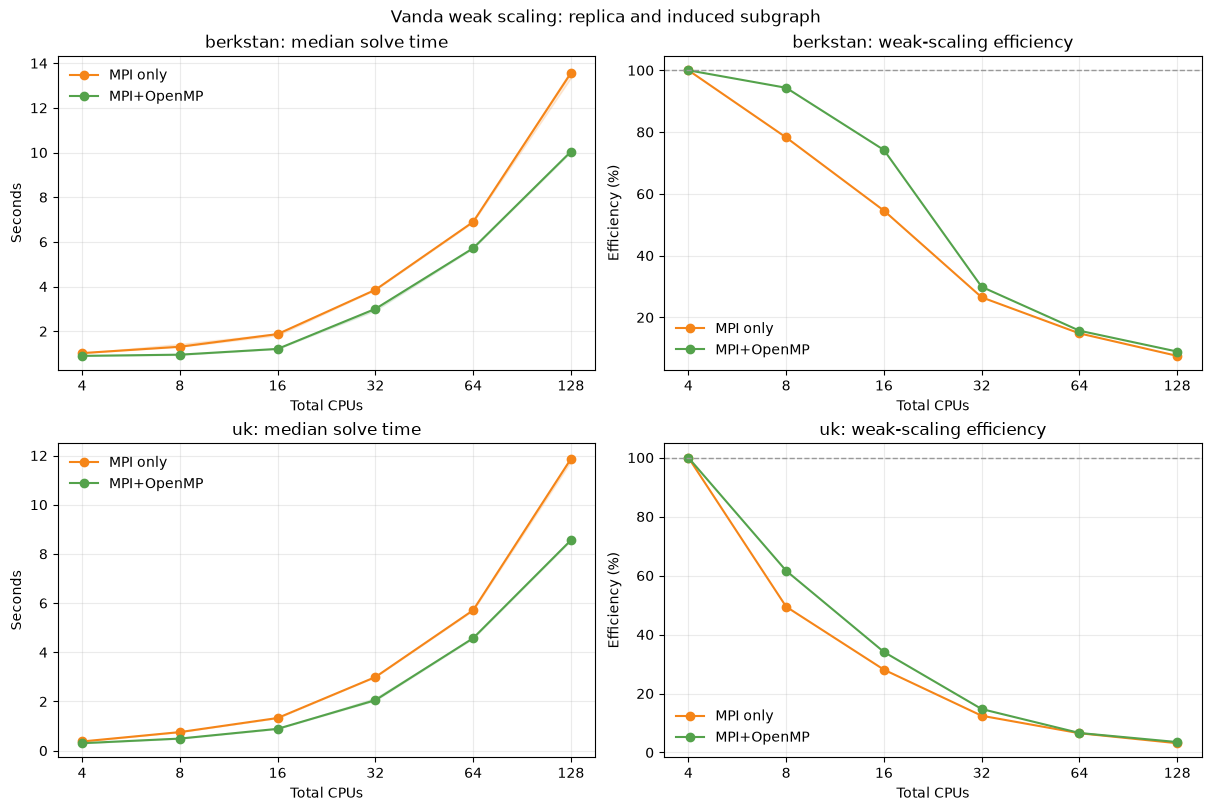

In [15]:
fig, axes = plt.subplots(2,2,figsize=(12,8),constrained_layout=True)
weak_colors={'MPI only':'#F58518','MPI+OpenMP':'#54A24B'}
for row,family in enumerate(['berkstan','uk']):
    for implementation in ['MPI only','MPI+OpenMP']:
        part=weak_summary[(weak_summary['family'].eq(family)) &
                          (weak_summary['implementation'].eq(implementation))].sort_values('total_cpus')
        axes[row,0].plot(part['total_cpus'],part['median_s'],marker='o',
                         label=implementation,color=weak_colors[implementation])
        axes[row,0].fill_between(part['total_cpus'],part['q1_s'],part['q3_s'],
                                 color=weak_colors[implementation],alpha=.15)
        axes[row,1].plot(part['total_cpus'],100*part['weak_efficiency'],marker='o',
                         label=implementation,color=weak_colors[implementation])
    axes[row,0].set_title(f'{family}: median solve time')
    axes[row,0].set_ylabel('Seconds')
    axes[row,1].set_title(f'{family}: weak-scaling efficiency')
    axes[row,1].set_ylabel('Efficiency (%)')
    axes[row,1].axhline(100,color='#999999',linestyle='--',linewidth=1)
    for col in range(2):
        axes[row,col].set_xscale('log',base=2)
        axes[row,col].set_xticks([4,8,16,32,64,128],[4,8,16,32,64,128])
        axes[row,col].set_xlabel('Total CPUs')
        axes[row,col].grid(alpha=.25)
        axes[row,col].legend(frameon=False)
fig.suptitle('Vanda weak scaling: replica and induced subgraph')
weak_path=FIGURES/'vanda_weak_runtime_efficiency.png'
fig.savefig(weak_path,dpi=180,bbox_inches='tight')
print('Saved:', weak_path.relative_to(ROOT))
plt.show()

## 12. Strong-Scaling vs Weak-Scaling

Strong scaling fixes the graph, so ideal runtime falls as CPUs increase. Weak scaling grows the graph with the CPU count, so ideal runtime stays constant. BerkStan strong scaling uses one graph, whereas weak scaling uses 1–32 replicas. UK strong scaling always uses the full graph, whereas induced scaling grows from a 1/32 sample to the full graph.

The hybrid rank/thread layouts differ between the two suites, so the figure compares trends rather than identical configurations at each CPU count.

Saved: results/vanda/figures/vanda_strong_vs_weak.png


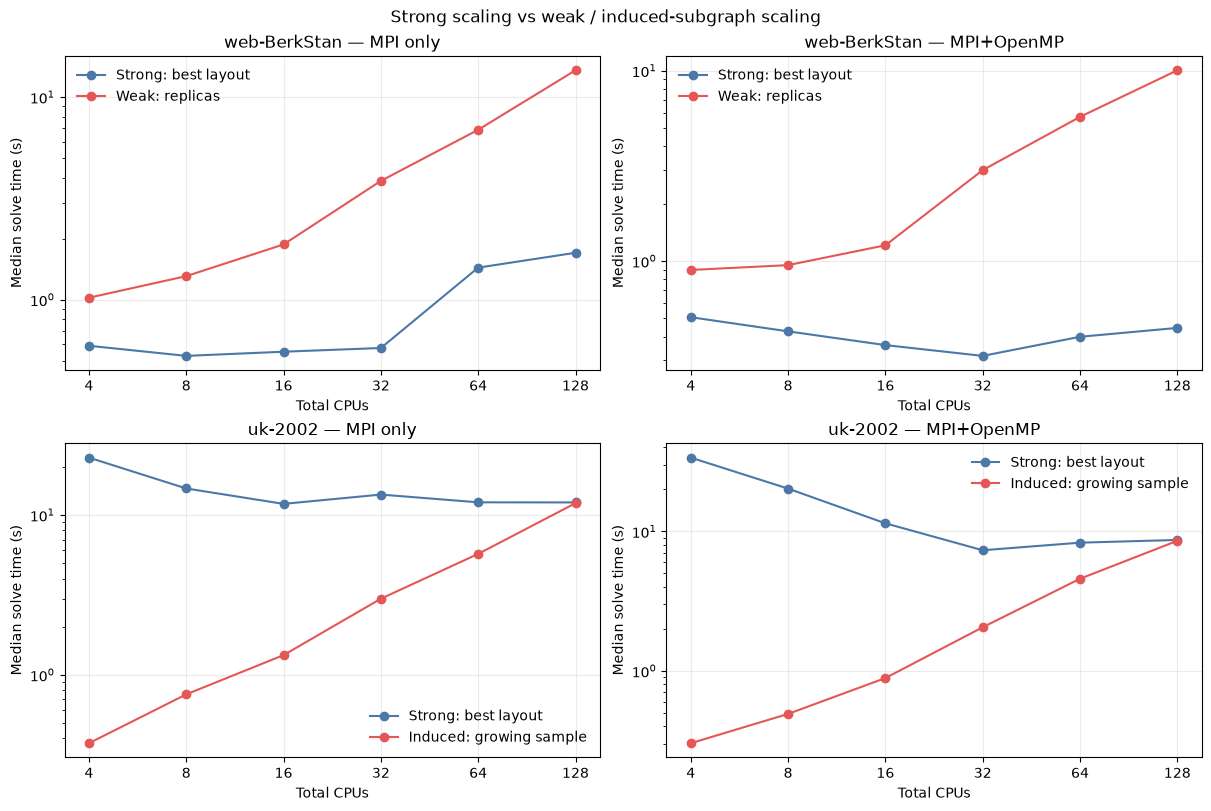

In [16]:
comparison_map={'berkstan':'web-BerkStan','uk':'uk-2002'}
fig,axes=plt.subplots(2,2,figsize=(12,8),constrained_layout=True)
for row,family in enumerate(['berkstan','uk']):
    dataset=comparison_map[family]
    for col,implementation in enumerate(['MPI only','MPI+OpenMP']):
        strong_part=strong_impl_best[(strong_impl_best['dataset_name'].eq(dataset)) &
                                     (strong_impl_best['implementation'].eq(implementation)) &
                                     (strong_impl_best['total_cpus'].ge(4))].sort_values('total_cpus')
        weak_part=weak_summary[(weak_summary['family'].eq(family)) &
                               (weak_summary['implementation'].eq(implementation))].sort_values('total_cpus')
        ax=axes[row,col]
        ax.plot(strong_part['total_cpus'],strong_part['median_s'],marker='o',
                label='Strong: best layout',color='#4C78A8')
        weak_label='Weak: replicas' if family=='berkstan' else 'Induced: growing sample'
        ax.plot(weak_part['total_cpus'],weak_part['median_s'],marker='o',
                label=weak_label,color='#E45756')
        ax.set_xscale('log',base=2); ax.set_yscale('log')
        ax.set_xticks([4,8,16,32,64,128],[4,8,16,32,64,128])
        ax.set_title(f'{dataset} — {implementation}')
        ax.set_xlabel('Total CPUs'); ax.set_ylabel('Median solve time (s)')
        ax.grid(alpha=.25); ax.legend(frameon=False)
fig.suptitle('Strong scaling vs weak / induced-subgraph scaling')
compare_path=FIGURES/'vanda_strong_vs_weak.png'
fig.savefig(compare_path,dpi=180,bbox_inches='tight')
print('Saved:', compare_path.relative_to(ROOT))
plt.show()

## 13. Why Weak Scaling Is Not Flat

BerkStan keeps local graph work and 148 iterations constant, but communication per rank does not stay constant. Every rank stores a full score vector, and each iteration performs an `Allgatherv` whose received data grows with the global graph (`N ∝ P`). `Allreduce` latency, memory traffic, cache pressure, and cross-node networking add further overhead. Thus hybrid runtime rises from 0.897 s at 4 CPUs to 10.042 s at 128 CPUs, even though the local workload is fixed.

UK induced scaling is not strict weak scaling: edges/CPU grows by about 19.7×, so its increase also reflects more local work and topology changes. Hybrid remains about 1.14–1.55× faster than MPI-only because fewer MPI ranks reduce collective-communication overhead.